# Bài thực hành 4 – TV5: Khoảng cách Hamming và so khớp

Mục tiêu: nhận mã hash (từ TV4) → tính khoảng cách Hamming giữa các cặp ảnh → phân loại tương tự / không tương tự theo ngưỡng → xuất bảng khoảng cách & dự đoán cho TV6 tính ROC.

**Quy ước thống nhất với TV6**
- `label`: 1 = cặp tương tự, 0 = không tương tự
- `distance`: số bit khác nhau, **càng nhỏ càng giống**
- Dự đoán: `1` nếu `distance < threshold` (đặt `INCLUSIVE = True` nếu nhóm thống nhất dùng `<=`)
- Khi vẽ ROC, dùng điểm số `-distance` (điểm cao = giống)

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

SRC_DIR = Path.cwd().parent / "src"
sys.path.insert(0, str(SRC_DIR))
from similarity import (hamming_distance, normalized_hamming, build_distance_table,
                        sweep_thresholds, evaluate_thresholds, to_bits)


INCLUSIVE = False          # False: distance < threshold | True: distance <= threshold
HASH_FILE  = "hashes.json" # {image_id: "0101..."}  do TV4 xuất ra
PAIRS_FILE = "pairs.csv"   # cột: img1,img2,label    do TV1/TV2 xuất ra

## 1. Hàm `hamming_distance()` và kiểm thử cơ bản

In [2]:
print(hamming_distance("10110", "10011"))               # 2
print(hamming_distance([1,0,1,1,0], np.array([1,0,0,1,1])))  # 2 (list / ndarray cũng được)
print(hamming_distance("1111", "1111"))                 # 0
print(normalized_hamming("1010", "0101"))               # 1.0

2
2
0
1.0


## 2. Kiểm tra đầu vào không hợp lệ / hash độ dài không đồng nhất

In [3]:
bad_cases = {
    "độ dài khác nhau": ("1010", "101"),
    "hash rỗng": ("", "1010"),
    "ký tự lạ": ("10a0", "1010"),
    "giá trị ngoài {0,1}": ([0, 1, 2], [0, 1, 1]),
    "None": (None, "1010"),
    "sai kiểu (int)": (1010, "1010"),
    "mảng 2 chiều": (np.zeros((2, 2)), np.zeros((2, 2))),
}
for name, (a, b) in bad_cases.items():
    try:
        hamming_distance(a, b)
        print(f"[KHÔNG BÁO LỖI] {name}")
    except (ValueError, TypeError) as e:
        print(f"[OK] {name:22s} -> {type(e).__name__}: {e}")

[OK] độ dài khác nhau       -> ValueError: Hash có độ dài khác nhau: 4 vs 3
[OK] hash rỗng              -> ValueError: Hash rỗng
[OK] ký tự lạ               -> ValueError: Hash chuỗi chỉ được chứa ký tự '0' và '1'
[OK] giá trị ngoài {0,1}    -> ValueError: Hash chỉ được chứa giá trị 0 hoặc 1
[OK] None                   -> TypeError: Hash là None
[OK] sai kiểu (int)         -> TypeError: Kiểu hash không được hỗ trợ: int
[OK] mảng 2 chiều           -> ValueError: Hash phải là mảng 1 chiều (hãy flatten trước)


## 3. Nạp dữ liệu hash và danh sách cặp ảnh
Nếu chưa có `hashes.json` / `pairs.csv` từ TV4, notebook tạo **dữ liệu giả lập** (cặp tương tự = lật ít bit, cặp khác = hash ngẫu nhiên, có chèn vài hash lỗi) để chạy thử pipeline. Khi có dữ liệu thật chỉ cần đặt file vào cùng thư mục.

In [4]:
if os.path.exists(HASH_FILE) and os.path.exists(PAIRS_FILE):
    with open(HASH_FILE) as f:
        hashes = json.load(f)
    pairs = pd.read_csv(PAIRS_FILE)
    print("Dùng dữ liệu thật:", len(hashes), "ảnh,", len(pairs), "cặp")
else:
    rng = np.random.default_rng(42)
    L, n = 64, 100
    hashes, rows = {}, []
    for i in range(n):
        base = rng.integers(0, 2, L)
        hashes[f"img{i}_a"] = "".join(map(str, base))
        flip = base.copy(); idx = rng.choice(L, rng.integers(2, 14), replace=False); flip[idx] ^= 1
        hashes[f"img{i}_b"] = "".join(map(str, flip))
        rows.append((f"img{i}_a", f"img{i}_b", 1))                   # cặp tương tự
    for i in range(n):
        j = (i + 1 + rng.integers(0, n - 1)) % n
        rows.append((f"img{i}_a", f"img{j}_b", 0))                   # cặp không tương tự
    # chèn trường hợp lỗi để kiểm tra
    hashes["bad_len"] = "1010"; hashes["bad_chr"] = "10x1" * 16
    rows += [("img0_a", "bad_len", 0), ("img1_a", "bad_chr", 0), ("img2_a", "ghost", 0)]
    pairs = pd.DataFrame(rows, columns=["img1", "img2", "label"])
    print("Dùng dữ liệu GIẢ LẬP:", len(hashes), "ảnh,", len(pairs), "cặp")
pairs.head()

Dùng dữ liệu GIẢ LẬP: 202 ảnh, 203 cặp


,img1,img2,label
0,img0_a,img0_b,1
1,img1_a,img1_b,1
2,img2_a,img2_b,1
3,img3_a,img3_b,1
4,img4_a,img4_b,1


## 4. Bảng khoảng cách giữa các cặp ảnh

In [5]:
table = build_distance_table(hashes, pairs)
print(table["status"].value_counts())
table[table["status"] != "ok"]      # các cặp bị loại do hash lỗi

status
ok                 200
length_mismatch      1
invalid_hash         1
missing_hash         1
Name: count, dtype: int64


,img1,img2,label,hash_len,distance,norm_distance,status
200,img0_a,bad_len,0,NaN,NaN,NaN,length_mismatch
201,img1_a,bad_chr,0,NaN,NaN,NaN,invalid_hash
202,img2_a,ghost,0,NaN,NaN,NaN,missing_hash


       count   mean   std   min   25%   50%   75%   max
label                                                  
0      100.0  32.25  4.21  21.0  30.0  32.0  35.0  45.0
1      100.0   7.39  3.09   2.0   5.0   7.0  10.0  13.0


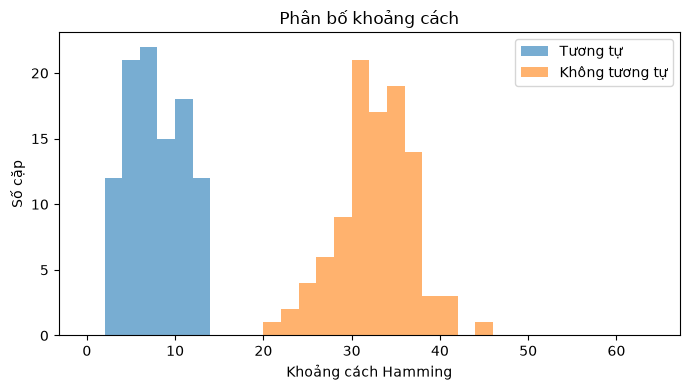

In [6]:
ok = table[table["status"] == "ok"]
print(ok.groupby("label")["distance"].describe().round(2))
plt.figure(figsize=(7, 4))
for lab, name in [(1, "Tương tự"), (0, "Không tương tự")]:
    plt.hist(ok.loc[ok.label == lab, "distance"], bins=range(0, int(ok.hash_len.max()) + 2, 2),
             alpha=0.6, label=name)
plt.xlabel("Khoảng cách Hamming"); plt.ylabel("Số cặp"); plt.legend(); plt.title("Phân bố khoảng cách")
plt.tight_layout(); plt.show()

## 5. Quy tắc phân loại theo ngưỡng – thử nhiều ngưỡng

In [7]:
max_len = int(ok.hash_len.max())
thresholds = list(range(2, max_len // 2 + 1, 2))   # có thể đổi bước/khoảng
pred_table = sweep_thresholds(table, thresholds, inclusive=INCLUSIVE)
pred_table.head(10)

,img1,img2,label,hash_len,distance,norm_distance,status,pred_t2,pred_t4,pred_t6,...,pred_t14,pred_t16,pred_t18,pred_t20,pred_t22,pred_t24,pred_t26,pred_t28,pred_t30,pred_t32
0,img0_a,img0_b,1,64.0,6.0,0.093750,ok,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,img1_a,img1_b,1,64.0,13.0,0.203125,ok,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,img2_a,img2_b,1,64.0,7.0,0.109375,ok,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,img3_a,img3_b,1,64.0,5.0,0.078125,ok,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,img4_a,img4_b,1,64.0,13.0,0.203125,ok,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,img5_a,img5_b,1,64.0,7.0,0.109375,ok,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,img6_a,img6_b,1,64.0,11.0,0.171875,ok,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,img7_a,img7_b,1,64.0,4.0,0.062500,ok,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
8,img8_a,img8_b,1,64.0,7.0,0.109375,ok,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
9,img9_a,img9_b,1,64.0,2.0,0.031250,ok,0.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [8]:
summary = evaluate_thresholds(table, thresholds, inclusive=INCLUSIVE)
summary.round(3)

,threshold,TP,FP,TN,FN,accuracy,sensitivity,specificity
0,2,0,0,100,100,0.500,0.00,1.00
1,4,12,0,100,88,0.560,0.12,1.00
2,6,33,0,100,67,0.665,0.33,1.00
3,8,55,0,100,45,0.775,0.55,1.00
4,10,70,0,100,30,0.850,0.70,1.00
5,12,88,0,100,12,0.940,0.88,1.00
6,14,100,0,100,0,1.000,1.00,1.00
7,16,100,0,100,0,1.000,1.00,1.00
8,18,100,0,100,0,1.000,1.00,1.00
9,20,100,0,100,0,1.000,1.00,1.00


Ngưỡng tham khảo (Youden J lớn nhất): 14 | sens=1.000, spec=1.000, acc=1.000


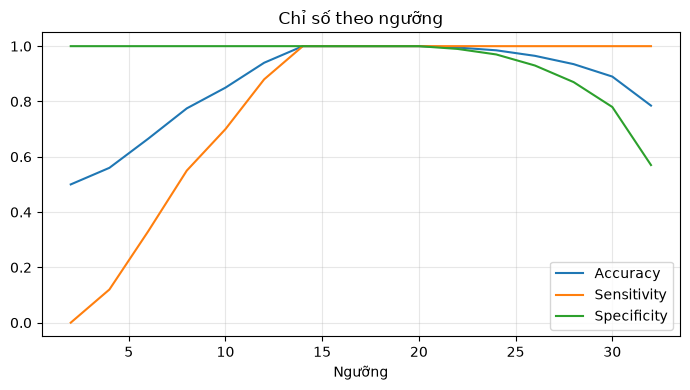

In [9]:
best = summary.assign(youden=summary.sensitivity + summary.specificity - 1).sort_values("youden", ascending=False).iloc[0]
print("Ngưỡng tham khảo (Youden J lớn nhất):", int(best.threshold),
      f"| sens={best.sensitivity:.3f}, spec={best.specificity:.3f}, acc={best.accuracy:.3f}")
plt.figure(figsize=(7, 4))
plt.plot(summary.threshold, summary.accuracy, label="Accuracy")
plt.plot(summary.threshold, summary.sensitivity, label="Sensitivity")
plt.plot(summary.threshold, summary.specificity, label="Specificity")
plt.xlabel("Ngưỡng"); plt.legend(); plt.grid(alpha=.3); plt.title("Chỉ số theo ngưỡng"); plt.tight_layout(); plt.show()

## 6. Xuất file bàn giao cho TV6

In [10]:
os.makedirs("output", exist_ok=True)
pred_table.to_csv("output/distance_predictions.csv", index=False)   # cho TV6 tính ROC
summary.to_csv("output/threshold_summary.csv", index=False)
print("Đã lưu output/distance_predictions.csv và output/threshold_summary.csv")

Đã lưu output/distance_predictions.csv và output/threshold_summary.csv


## 7. Ghi chú bàn giao
- `distance_predictions.csv`: `img1, img2, label, hash_len, distance, norm_distance, status, pred_t<ngưỡng>...`. Cặp `status != ok` có `distance = NaN` → TV6 cần lọc `status == "ok"` trước khi tính ROC.
- Với ROC dùng cột `distance` làm điểm số **đảo dấu** (`-distance`) để điểm cao ứng với "giống".
- Cần thống nhất với TV6: dấu so sánh (`<` hay `<=`) và tập ngưỡng quét.